1D Bspline

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
import sys
sys.path.append(r'C:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines')  # Adjust path accordingly

from plot_style import set_plot_style

set_plot_style()

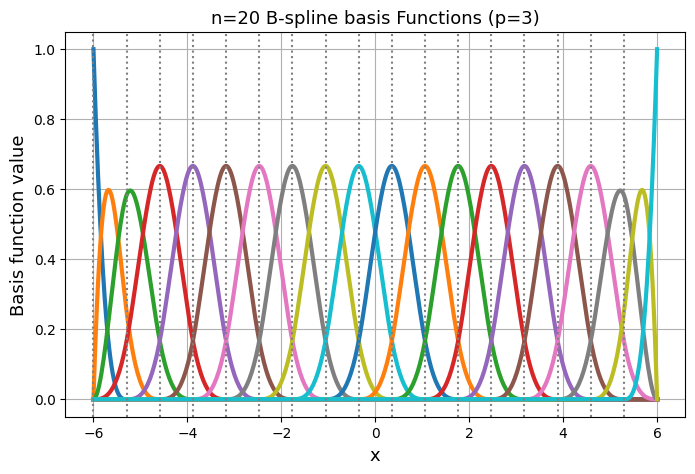

In [2]:


# Degree of B-spline (order = degree + 1)
degree = 3  # Quadratic B-spline

# Knot vector (uniform, clamped)--> defines the basis functions
# For n basis functions of degree p, use n + p + 1 knots
# Each element is affected by p+1 bsplines.
# Uniform clamped, that means we repeat degree times the end and start values to enforce that 
# bsplines start and end at the boundaries.
n_basis = 20
n_knots = n_basis + degree + 1
knot_vector = torch.linspace(-6, 6, n_knots - 2 * degree)
knot_vector = torch.cat((
    torch.full((degree,), knot_vector[0]),
    knot_vector,
    torch.full((degree,), knot_vector[-1])
))

# Evaluation grid
x = torch.linspace(-6, 6, 500)


# Cox-de Boor recursion formula
def bspline_basis(i, p, x, knots):
    if p == 0:
        return ((x >= knots[i]) & (x <= knots[i+1])).float()
    else:
        denom1 = knots[i+p] - knots[i]
        denom2 = knots[i+p+1] - knots[i+1]

        term1 = 0.0
        if denom1 > 0:
            term1 = (x - knots[i]) / denom1 * bspline_basis(i, p-1, x, knots)

        term2 = 0.0
        if denom2 > 0:
            term2 = (knots[i+p+1] - x) / denom2 * bspline_basis(i+1, p-1, x, knots)

        return term1 + term2

# Plot all basis functions
plt.figure(figsize=(8, 5))
y = torch.zeros(n_basis, x.shape[0])
for i in range(n_basis):
    y[i] = bspline_basis(i, degree, x, knot_vector)
    plt.plot(x, y[i], label=f"B{i},{degree}",linewidth=3)

for x in knot_vector[3:20]:
    plt.axvline(x=x, color='gray', linestyle=':')
plt.title(f"n=20 B-spline basis Functions (p={degree})", fontsize=13)
plt.xlabel("x", fontsize=13)
plt.ylabel("Basis function value", fontsize=13)
# plt.legend()
# for spine in plt.gca().spines.values():
#     spine.set_visible(False)
# plt.xticks([])  # Remove x-axis ticks
# plt.yticks([])  # Remove y-axis ticks
plt.grid(True)
# plt.savefig("basis.pdf")
plt.show()


In [11]:
plt.savefig("basis.pdf")

<Figure size 640x480 with 0 Axes>

In [13]:
knot_vector

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0588, 0.1176, 0.1765, 0.2353, 0.2941,
        0.3529, 0.4118, 0.4706, 0.5294, 0.5882, 0.6471, 0.7059, 0.7647, 0.8235,
        0.8824, 0.9412, 1.0000, 1.0000, 1.0000, 1.0000])

In [3]:
coeff = torch.tensor([2.,4.,2.])

In [4]:
bspline = coeff@y[1:-1]

In [3]:
import torch


x = torch.linspace(0,0.99,1000, requires_grad=True)


class bsplines:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        self.nodal_values = torch.zeros(n_basis-2, requires_grad=True)

    def forward(self,x):

        def bspline_basis(i, p, x, knots):
            if p == 0:
                return ((x >= knots[i]) & (x <= knots[i+1])).float()
            else:
                denom1 = knots[i+p] - knots[i]
                denom2 = knots[i+p+1] - knots[i+1]

                term1 = 0.0
                if denom1 > 0:
                    term1 = (x - knots[i]) / denom1 * bspline_basis(i, p-1, x, knots)

                term2 = 0.0
                if denom2 > 0:
                    term2 = (knots[i+p+1] - x) / denom2 * bspline_basis(i+1, p-1, x, knots)

                return term1 + term2
        
        y = torch.zeros(self.n_basis, x.shape[0])
        for i in range(self.n_basis):
            y[i] = bspline_basis(i, self.degree, x, self.knot_vector)
                
        bspline = self.nodal_values@y[1:-1]

        return bspline


In [4]:
model = bsplines(5,2)

In [5]:
# Learning rate
learning_rate = 0.001

# Number of iterations
epochs = 1000

# Training loop (manual gradient descent)
for epoch in range(epochs):
    # Forward pass: y = slope * x + intercept
    # y_pred = torch.einsum('bij,bi->j',phi, nodal_values)
    y_pred = model.forward(x)
    
    # Compute model first derivative wrt x
    grad_u_x=torch.autograd.grad(y_pred, x, grad_outputs=torch.ones_like(y_pred), create_graph=True)[0]

    # Compute model second derivative wrt x
    grad_u_xx=torch.autograd.grad(grad_u_x, x, grad_outputs=torch.ones_like(y_pred), create_graph=True)[0]

    # physics loss
    # loss = torch.mean((grad_u_x - 2*x) ** 2) 
    # loss = torch.mean((grad_u_xx - 2) ** 2)/10
    # Poisson 
    loss = torch.mean((grad_u_xx + 1) ** 2)

    # Compute Mean Squared Error (MSE) loss
    # loss = torch.mean((y_pred - y) ** 2)
    
    # Backward pass: compute gradients
    loss.backward()
    
    # Manually update parameters using the gradients
    with torch.no_grad():
        model.nodal_values -= learning_rate * model.nodal_values.grad
    
    # Zero the gradients after each update
    model.nodal_values.grad.zero_()
    # x.grad.zero_()
    
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/1000], Loss: 0.5714803338050842
Epoch [10/1000], Loss: 0.3273034989833832
Epoch [15/1000], Loss: 0.18745630979537964
Epoch [20/1000], Loss: 0.10736165940761566
Epoch [25/1000], Loss: 0.061489228159189224
Epoch [30/1000], Loss: 0.03521667793393135
Epoch [35/1000], Loss: 0.020169604569673538
Epoch [40/1000], Loss: 0.011551734060049057
Epoch [45/1000], Loss: 0.006616014055907726
Epoch [50/1000], Loss: 0.0037891995161771774
Epoch [55/1000], Loss: 0.002170178107917309
Epoch [60/1000], Loss: 0.0012429326307028532
Epoch [65/1000], Loss: 0.0007118638604879379
Epoch [70/1000], Loss: 0.0004076998447999358
Epoch [75/1000], Loss: 0.00023350637638941407
Epoch [80/1000], Loss: 0.00013373342517297715
Epoch [85/1000], Loss: 7.659191032871604e-05
Epoch [90/1000], Loss: 4.3867261410923675e-05
Epoch [95/1000], Loss: 2.5125042157014832e-05
Epoch [100/1000], Loss: 1.4389132957148831e-05
Epoch [105/1000], Loss: 8.24035032565007e-06
Epoch [110/1000], Loss: 4.7192802412610035e-06
Epoch [115/1000], Lo

In [10]:
np.save('y_pred_sp.npy', y_pred.detach().numpy())


In [2]:
y_pred_FEM = np.load('y_pred_FEM.npy')
y_pred_sp = np.load('y_pred_sp.npy')

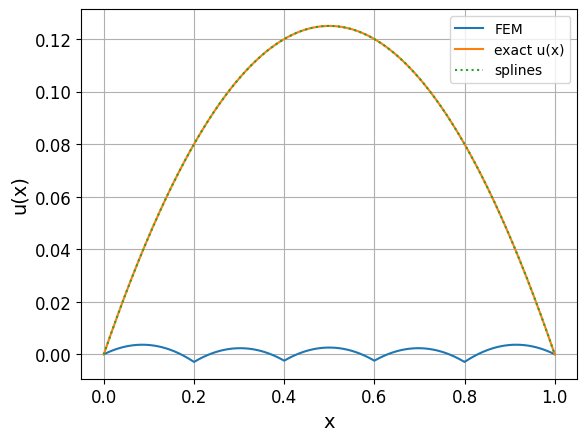

In [8]:
x = torch.linspace(0,0.99999,1000, requires_grad=True)
# y_pred = model.forward(x)

plt.plot(x.detach().numpy(),y_pred_FEM, label="FEM")
plt.plot(x.detach().numpy(), -(x.detach().numpy()**2)/2+1/2*x.detach().numpy(), label="exact u(x)")
plt.plot(x.detach().numpy(),y_pred_sp,':', label="splines")
plt.legend()
# plt.yscale('log')
# plt.title("Losses",fontsize=14)
plt.xlabel("x",fontsize=14)
plt.ylabel("u(x)",fontsize=14)
plt.tick_params(axis='both', labelsize=12)
plt.grid(True)

plt.savefig("FEM_splines.pdf", dpi=300)
plt.show()

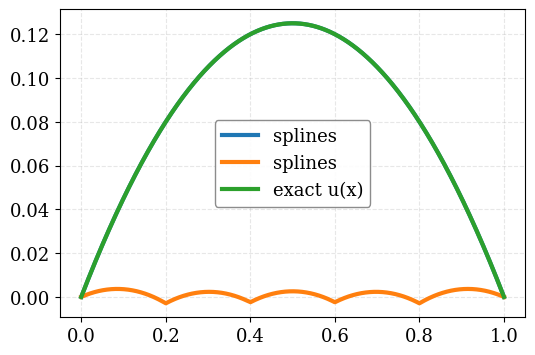

In [7]:
x = torch.linspace(0,0.99999,1000, requires_grad=True)
y_pred = model.forward(x)
plt.plot(x.detach().numpy(),y_pred.detach().numpy(), label="splines")
plt.plot(x.detach().numpy(),y_pred_FEM, label="splines")
plt.plot(x.detach().numpy(), -(x.detach().numpy()**2)/2+1/2*x.detach().numpy(), label="exact u(x)")
plt.legend()
plt.show()


In [ ]:
plt.figure(figsize=(8, 5))
y = torch.zeros(n_basis, x.shape[0])
for i in range(n_basis):
    y[i] = bspline_basis(i, degree, x, knot_vector)
    plt.plot(x, y[i], label=f"B{i},{degree}",linewidth=3)

for x in knot_vector[3:20]:
    plt.axvline(x=x, color='gray', linestyle=':')
plt.title(f"n=20 B-spline basis Functions (p={degree})", fontsize=13)
plt.xlabel("x", fontsize=13)
plt.ylabel("Basis function value", fontsize=13)
# plt.legend()
# for spine in plt.gca().spines.values():
#     spine.set_visible(False)
# plt.xticks([])  # Remove x-axis ticks
# plt.yticks([])  # Remove y-axis ticks
plt.grid(True)
# plt.savefig("basis.pdf")
plt.show()

2D Bsplines

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [8]:
class bsplines:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        # 2D trainable coefficients
        self.coeffs = torch.rand(n_basis, n_basis, requires_grad=True)

        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            return ((x >= knots[i]) & (x < knots[i+1])).float()
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_y = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_y) for j in range(self.n_basis)])
        y = torch.zeros(x.shape[0])

        for i in range(1,(self.n_basis-1)):
            for j in range(1,(self.n_basis-1)):
                y += self.coeffs[i, j] * self.B_x[i]*self.B_y[j]
        

        return y

In [9]:
model = bsplines(10,2)

In [10]:
colloc_points = 1000
x = torch.linspace(0,0.99,colloc_points, requires_grad=True).reshape(x.shape[0],1)
y = torch.linspace(0,0.99,colloc_points, requires_grad=True).reshape(x.shape[0],1)

In [11]:
epochs = 100000
learning_rate=1e-3
for epoch in range(epochs):
    
    
    u = model.forward(torch.cat([x, y], dim=1))
    
    grads = torch.autograd.grad(u, [x, y], grad_outputs=torch.ones_like(u), create_graph=True)
    u_x, u_y = grads
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, y, grad_outputs=torch.ones_like(u_y), create_graph=True)[0]
    # Residual loss
    res = u_xx + u_yy + 1
    loss = torch.mean(res**2)
    
    loss.backward()
    
    # Manually update parameters using the gradients
    with torch.no_grad():
        model.coeffs -= learning_rate * model.coeffs
    # Zero the gradients after each update
    model.coeffs.grad.zero_()
    # x.grad.zero_()
    
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/100000], Loss: 5549.109375
Epoch [10/100000], Loss: 5493.68798828125
Epoch [15/100000], Loss: 5438.81884765625
Epoch [20/100000], Loss: 5384.498046875
Epoch [25/100000], Loss: 5330.71923828125
Epoch [30/100000], Loss: 5277.47509765625
Epoch [35/100000], Loss: 5224.7626953125
Epoch [40/100000], Loss: 5172.576171875
Epoch [45/100000], Loss: 5120.9091796875
Epoch [50/100000], Loss: 5069.75830078125
Epoch [55/100000], Loss: 5019.11669921875
Epoch [60/100000], Loss: 4968.98095703125
Epoch [65/100000], Loss: 4919.34521484375
Epoch [70/100000], Loss: 4870.2041015625
Epoch [75/100000], Loss: 4821.55322265625
Epoch [80/100000], Loss: 4773.38720703125
Epoch [85/100000], Loss: 4725.7021484375
Epoch [90/100000], Loss: 4678.4921875
Epoch [95/100000], Loss: 4631.7529296875
Epoch [100/100000], Loss: 4585.47998046875
Epoch [105/100000], Loss: 4539.66943359375
Epoch [110/100000], Loss: 4494.31494140625
Epoch [115/100000], Loss: 4449.41357421875
Epoch [120/100000], Loss: 4404.958984375
Epoch [1

KeyboardInterrupt: 

In [6]:
plt.figure(figsize=(8, 5))


for i in range(model.n_basis):
    
    plt.plot(x, model.B_y[i],'*', label=f"B{i},{model.degree}")
plt.title(f"B-spline Basis Functions (degree={model.degree})")
plt.xlabel("x")
plt.ylabel("Basis value")
plt.legend()
plt.grid(True)
plt.show()

AttributeError: 'bsplines' object has no attribute 'B_y'

<Figure size 800x500 with 0 Axes>

In [11]:
torch.where(y==0)

(tensor([], dtype=torch.int64),)

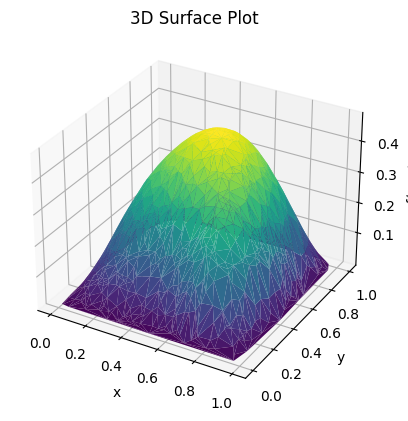

In [10]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_trisurf(x[:, 0], x[:, 1], y.detach().numpy(), cmap='viridis', linewidth=0.2)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('f(x, y)')
plt.title('3D Surface Plot')
plt.show()


In [2]:
# Degree of B-spline (order = degree + 1)
degree = 2  # Quadratic B-spline

# Knot vector (uniform, clamped)--> defines the basis functions
# For n basis functions of degree p, use n + p + 1 knots
# Uniform clamped, that means we repeat degree times the end and start values to enforce that 
# bsplines start and end at the boundaries.
n_basis = 5
n_knots = n_basis + degree + 1
knot_vector = torch.linspace(0, 1, n_knots - 2 * degree)
knot_vector = torch.cat((
    torch.full((degree,), knot_vector[0]),
    knot_vector,
    torch.full((degree,), knot_vector[-1])
))




# Cox-de Boor recursion formula
def bspline_basis(i, p, x, knots):
    if p == 0:
        return ((x >= knots[i]) & (x < knots[i+1])).float()
    else:
        denom1 = knots[i+p] - knots[i]
        denom2 = knots[i+p+1] - knots[i+1]

        term1 = 0.0
        if denom1 > 0:
            term1 = (x - knots[i]) / denom1 * bspline_basis(i, p-1, x, knots)

        term2 = 0.0
        if denom2 > 0:
            term2 = (knots[i+p+1] - x) / denom2 * bspline_basis(i+1, p-1, x, knots)

        return term1 + term2

In [3]:
knot_x = knot_vector.clone()
knot_y = knot_vector.clone()


In [4]:
# define number of 2d collocation points.

colloc_points = 1000
x = torch.rand(colloc_points,2)
B_x = torch.stack([bspline_basis(i, degree, x[:,0], knot_x ) for i in range(n_basis)])
B_y = torch.stack([bspline_basis(j, degree, x[:,1],knot_y) for j in range(n_basis)])

In [5]:
# Model after linear interpolation of the Bsplines.
coeffs = torch.rand(n_basis, n_basis)

y = torch.zeros(x.shape[0])

for i in range(n_basis):
    for j in range(n_basis):
        y += coeffs[i, j] * B_x[i]*B_y[j]

In [5]:
# Create meshgrid
X, Y = torch.meshgrid(x[:,0], x[:,1], indexing='ij')
Z = torch.zeros_like(X)

# Random coefficients for surface
coeffs = torch.rand(n_basis, n_basis)

# Build the surface as a linear combination of tensor products
for i in range(n_basis):
    for j in range(n_basis):
        Z += coeffs[i, j] * torch.outer(B_x[i], B_y[j])


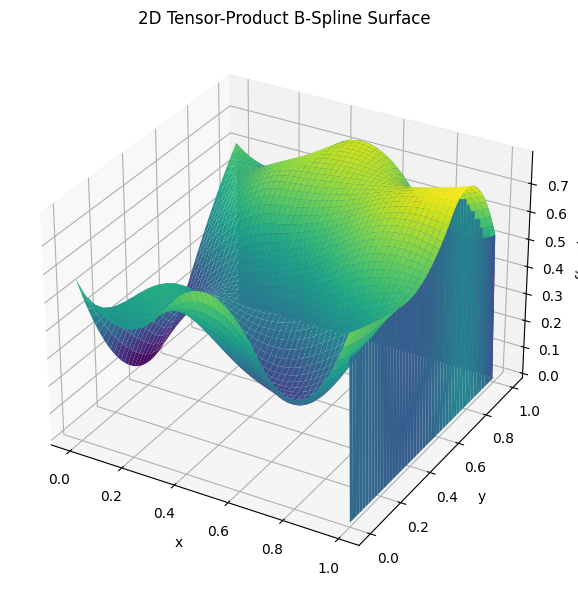

In [10]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

X_np, Y_np, Z_np = X.numpy(), Y.numpy(), Z.numpy()
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X_np, Y_np, Z_np, cmap='viridis')
ax.set_title("2D Tensor-Product B-Spline Surface")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x, y)")
plt.tight_layout()
plt.show()


In [5]:
import torch

# Tensors
A = torch.randn(5, 5)           # (i, j)
B = torch.randn(5, 5, 100)      # (i, j, k)

# Double contraction: sum over i and j, for each k
C = torch.einsum('ij,ijk->k', A, B)

print(C.shape)  # torch.Size([100])


torch.Size([100])


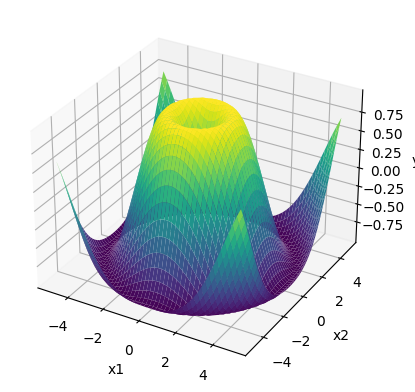

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define the input space
x1 = np.linspace(-5, 5, 50)
x2 = np.linspace(-5, 5, 50)
X1, X2 = np.meshgrid(x1, x2)

# Define the output function y = f(x1, x2)
Y = np.sin(np.sqrt(X1**2 + X2**2))

# Create a 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X1, X2, Y, cmap='viridis')

# Labels
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('y')

plt.show()
